In [74]:
from pathlib import Path    
import warnings    
import numpy as np    
import pandas as pd    
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
BASE_DIR = Path("..").resolve()    
RAW_DIR = BASE_DIR / "data" / "raw"    
PROCESSED_DIR = BASE_DIR / "data" / "processed"    
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [76]:
account_raw = pd.read_csv(RAW_DIR / "da_fitly_account_info.csv")    
support_raw = pd.read_csv(RAW_DIR / "da_fitly_customer_support.csv")    
activity_raw = pd.read_csv(RAW_DIR / "da_fitly_user_activity.csv")

In [77]:
datasets = {    
        "account_info": account_raw,    
        "customer_support": support_raw,    
        "user_activity": activity_raw,    
}         
for name, df in datasets.items():    
    print(f"--- {name} ---")    
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")    
    print(f"Columns: {list(df.columns)}\n")    


--- account_info ---
Shape: 400 rows x 6 columns
Columns: ['customer_id', 'email', 'state', 'plan', 'plan_list_price', 'churn_status']

--- customer_support ---
Shape: 918 rows x 7 columns
Columns: ['ticket_time', 'user_id', 'channel', 'topic', 'resolution_time_hours', 'state', 'comments']

--- user_activity ---
Shape: 445 rows x 3 columns
Columns: ['event_time', 'user_id', 'event_type']



# Data Understanding & Systematic Profiling

## Automated column-level audit helper    

In [78]:
def audit_dataframe(df: pd.DataFrame, name: str) -> pd.DataFrame:
    summary = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Non-Null": df.notna().sum(),
        "Null Count": df.isna().sum(),
        "Null (%)": (df.isna().mean() * 100).round(2),
        "Unique Values": df.nunique(dropna=True),
        "Memory (KB)": (df.memory_usage(deep=True, index=False) / 1024).round(2),
        "Sample Values": [
            df[col].dropna().unique()[:5].tolist()
            for col in df.columns
        ]
    })

    print(f"\n{'=' * 65}")
    print(f"DATA AUDIT: {name}")
    print(f"{'=' * 65}")

    print(f"Total Rows       : {df.shape[0]:,}")
    print(f"Total Columns    : {df.shape[1]:,}")
    print(f"Duplicate Rows   : {df.duplicated().sum():,}")
    print(f"Total Missing    : {df.isna().sum().sum():,}")
    print(f"Memory Usage     : {df.memory_usage(deep=True).sum() / 1024:.2f} KB")

    display(summary)

    return summary

In [79]:
audit_account = audit_dataframe(account_raw, "account_info")    


DATA AUDIT: account_info
Total Rows       : 400
Total Columns    : 6
Duplicate Rows   : 0
Total Missing    : 286
Memory Usage     : 110.27 KB


,Data Type,Non-Null,Null Count,Null (%),Unique Values,Memory (KB),Sample Values
customer_id,object,400,0,0.0,400,21.48,"[C10000, C10001, C10002, C10003, C10004]"
email,object,400,0,0.0,400,27.34,"[user10000@example.com, user10001@example.net,..."
state,object,400,0,0.0,50,22.41,"[New Jersey, Louisiana, Oklahoma, Michigan, Te..."
plan,object,400,0,0.0,4,21.27,"[Enterprise, Basic, Free, Pro]"
plan_list_price,int64,400,0,0.0,106,3.12,"[105, 22, 24, 0, 119]"
churn_status,object,114,286,71.5,1,14.50,[Y]


In [80]:
audit_support = audit_dataframe(support_raw, "customer_support") 


DATA AUDIT: customer_support
Total Rows       : 918
Total Columns    : 7
Duplicate Rows   : 0
Total Missing    : 872
Memory Usage     : 217.84 KB


,Data Type,Non-Null,Null Count,Null (%),Unique Values,Memory (KB),Sample Values
ticket_time,object,918,0,0.00,918,67.24,"[2025-06-13 05:55:17.154573, 2025-08-06 13:21:..."
user_id,int64,918,0,0.00,367,7.17,"[10125, 10109, 10149, 10268, 10041]"
channel,object,918,0,0.00,4,47.97,"[chat, phone, -, email]"
topic,object,918,0,0.00,4,50.20,"[technical, account, other, billing]"
resolution_time_hours,float64,918,0,0.00,735,7.17,"[11.48, 1.01, 10.09, 9.1, 2.28]"
state,int64,918,0,0.00,2,7.17,"[1, 0]"
comments,object,46,872,94.99,19,30.79,"[Erase my data from your systems., Request ful..."


In [81]:
audit_activity = audit_dataframe(activity_raw, "user_activity")    


DATA AUDIT: user_activity
Total Rows       : 445
Total Columns    : 3
Duplicate Rows   : 0
Total Missing    : 0
Memory Usage     : 62.79 KB


,Data Type,Non-Null,Null Count,Null (%),Unique Values,Memory (KB),Sample Values
event_time,object,445,0,0.0,445,32.59,"[2025-09-08 15:05:39.422721, 2025-09-08 08:15:..."
user_id,int64,445,0,0.0,246,3.48,"[10118, 10220, 10009, 10227, 10123]"
event_type,object,445,0,0.0,4,26.59,"[watch_video, share_workout, read_article, tra..."


### Systematic Data Audit Findings
1. **Missing Data Patterns:**
   - **churn_status in account_info (71.5% missing / 286 rows):** it indicates a semi-labeled target structure where `"Y"` denotes confirmed churn (114 users, 28.5%) and `NaN` represents active/retained users.
   - **comments in customer_support (94.99% missing / 872 rows):** Free-form user feedback is recorded only for exceptional escalations.
   - **`user_activity` (0% missing):** Completely populated telemetry logs across all columns.
2. **Key Data Types & Discrepancies:**
   - **ID Discrepancy:** `account_info.customer_id` is string-formatted with a `'C'` prefix (e.g., `'C10000'`), while `customer_support.user_id` and `user_activity.user_id` are integer-formatted (`10000`). Key standardization is required for joins.
   - **Temporal Columns:** `ticket_time` and `event_time` are stored as object strings requiring datetime parsing.
   - **Naming Ambiguity:** Both `account_info` and `customer_support` have a column named `state` (US geographical state vs. binary ticket resolution status). Renaming is necessary to prevent collisions.


# Deep-dive checks on categorical values, numeric distributions, and timestamps    

In [82]:
print("Account Info: Plan & Churn Status Crosstab (including NaN)")    
display(pd.crosstab(account_raw["plan"], account_raw["churn_status"].fillna("MISSING"), dropna=False))      

Account Info: Plan & Churn Status Crosstab (including NaN)


churn_status,MISSING,Y
plan,,
Basic,90,28
Enterprise,68,24
Free,62,43
Pro,66,19


In [83]:
print("\nAccount Info: Numeric Summary")    
display(account_raw.describe(include="all"))    


Account Info: Numeric Summary


,customer_id,email,state,plan,plan_list_price,churn_status
count,400,400,400,400,400.000000,114
unique,400,400,50,4,NaN,1
top,C10000,user10000@example.com,Virginia,Basic,NaN,Y
freq,1,1,16,118,NaN,114
mean,NaN,NaN,NaN,NaN,43.965000,NaN
std,NaN,NaN,NaN,NaN,45.263348,NaN
min,NaN,NaN,NaN,NaN,0.000000,NaN
25%,NaN,NaN,NaN,NaN,0.000000,NaN
50%,NaN,NaN,NaN,NaN,26.000000,NaN
75%,NaN,NaN,NaN,NaN,77.250000,NaN


### Churn Distribution
- **Baseline Churn Rate:** Overall churn rate is **28.5%** (114 churned out of 400 accounts).
- **Churn Risk by Subscription Tier:**
  - **Free Plan:** Shows the highest churn volume (**43 users**, ~41.0% churn rate). Free tier users exhibit significantly lower switching barriers and retention stickiness.
  - **Enterprise Plan:** 24 churned out of 92 users (~26.1% churn rate).
  - **Basic Plan:** 28 churned out of 118 users (~23.7% churn rate).
  - **Pro Plan:** 19 churned out of 85 users (~22.4% churn rate) — the lowest churn rate among all tiers.



=== Customer Support: Categorical Value Counts ===


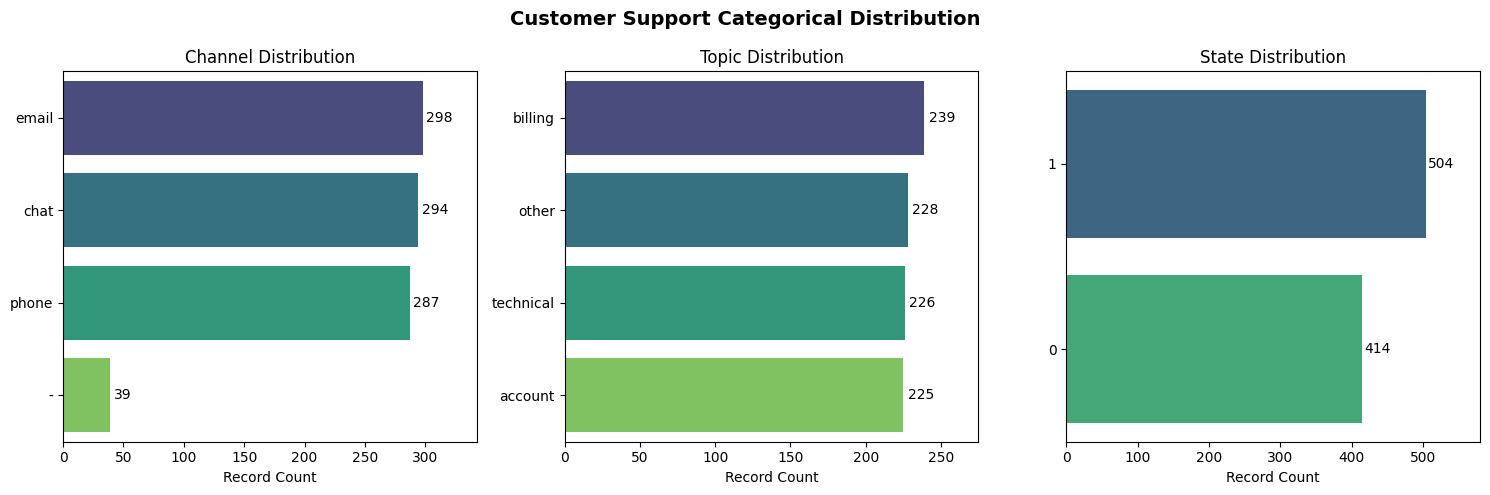

In [84]:
print("\n=== Customer Support: Categorical Value Counts ===")   
categorical_cols = ["channel", "topic", "state"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, categorical_cols):

    counts = support_raw[col].fillna("Missing").value_counts()

    sns.barplot(
        x=counts.values,
        y=counts.index.astype(str),
        hue=counts.index.astype(str),
        palette="viridis",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col.title()} Distribution")
    ax.set_xlabel("Record Count")
    ax.set_ylabel("")

    for i, value in enumerate(counts.values):
        ax.text(value + 3, i, str(value), va="center")

    ax.set_xlim(0, counts.max() * 1.15)

plt.suptitle("Customer Support Categorical Distribution",
             fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()


In [85]:
print("\n=== Customer Support: Numeric Summary ===")    
display(support_raw[["resolution_time_hours"]].describe())    


=== Customer Support: Numeric Summary ===


,resolution_time_hours
count,918.000000
mean,10.391362
std,7.079888
min,0.520000
25%,5.112500
50%,9.040000
75%,13.137500
max,32.460000


### Customer Support Profiling
- **Interaction Channels:** Live chat is the most preferred support medium, followed by phone calls and email. A placeholder token `'-'` exists for unknown channels (~minority).
- **Issue Topics:** Technical issues and billing inquiries represent the largest support volume, indicating potential friction points during app usage or renewal cycles.
- **Resolution Duration:** `resolution_time_hours` averages **10.39 hours** (median: 9.04 hrs, min: 0.52 hrs, max: 32.46 hrs). The distribution is positively skewed with no negative or zero anomalies.


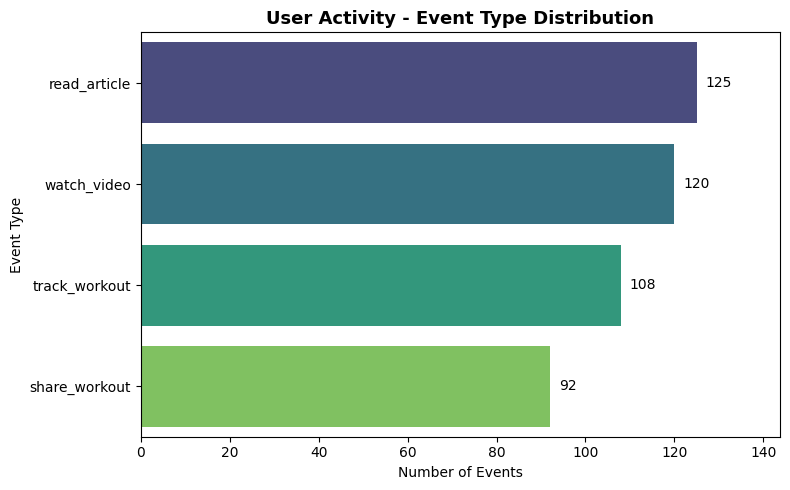

In [86]:
plt.figure(figsize=(8, 5))
counts = activity_raw["event_type"].fillna("Missing").value_counts()
sns.barplot(
    x=counts.values,
    y=counts.index,
    hue=counts.index,
    palette="viridis",
    legend=False
)

plt.title("User Activity - Event Type Distribution",
          fontsize=13, fontweight="bold")
plt.xlabel("Number of Events")
plt.ylabel("Event Type")

for i, value in enumerate(counts.values):
    plt.text(value + 2, i, f"{value:,}", va="center")

plt.xlim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()


### Interpretation: User Activity Patterns
- **Engagement Hierarchy:** `watch_video` and `share_workout` dominate user platform actions, followed by `track_workout` and `read_article`.
- **Behavioral Signal:** Activity volume per user will serve as a core behavioral indicator for engagement decay leading up to churn.


In [87]:
# Cross-table ID alignment & Referential Integrity check    
acc_ids_raw = account_raw["customer_id"].astype(str)    
print("Sample customer_id in account_info:", acc_ids_raw.head(5).tolist())    
print("Sample user_id in customer_support:", support_raw["user_id"].head(5).tolist())    
print("Sample user_id in user_activity:", activity_raw["user_id"].head(5).tolist())    

Sample customer_id in account_info: ['C10000', 'C10001', 'C10002', 'C10003', 'C10004']
Sample user_id in customer_support: [10125, 10109, 10149, 10268, 10041]
Sample user_id in user_activity: [10118, 10220, 10009, 10227, 10123]


In [88]:
# Normalize IDs temporarily to check overlap    
acc_id_nums = set(acc_ids_raw.str.replace(r"\D", "", regex=True).astype(int))    
sup_ids = set(support_raw["user_id"].dropna().astype(int))    
act_ids = set(activity_raw["user_id"].dropna().astype(int)) 

In [89]:
print(f"\nUnique customers in account_info: {len(acc_id_nums)}")    
print(f"Support users NOT in account_info (orphans): {len(sup_ids - acc_id_nums)}")    
print(f"Activity users NOT in account_info (orphans): {len(act_ids - acc_id_nums)}")    
print(f"Account users with ZERO support tickets: {len(acc_id_nums - sup_ids)}")    
print(f"Account users with ZERO activity logs: {len(acc_id_nums - act_ids)}")    


Unique customers in account_info: 400
Support users NOT in account_info (orphans): 0
Activity users NOT in account_info (orphans): 0
Account users with ZERO support tickets: 33
Account users with ZERO activity logs: 154


### Referential Integrity & Cohort Coverage
- **Referential Integrity:** 100% clean — **0 orphaned records** in either `customer_support` or `user_activity` (every user maps back to a valid customer in `account_info`).
- **Coverage & Inactivity Analysis:**
  - **33 customers (8.25%)** have never submitted a support ticket.
  - **154 customers (38.5%)** have **zero logged activity events**. This substantial dormant segment is a strong predictive signal for customer abandonment and churn.


In [90]:
# Check for upstream downtime / date gaps & GDPR requests
support_times = pd.to_datetime(support_raw["ticket_time"], errors="coerce")    
activity_times = pd.to_datetime(activity_raw["event_time"], errors="coerce")    

In [91]:
print("=== Timestamp Validation ===")

print("\nCustomer Support")
print(f"Date Range       : {support_times.min()} to {support_times.max()}")
print(f"Valid Timestamps : {support_times.notna().sum():,}")
print(f"Missing/Invalid  : {support_times.isna().sum():,}")

print("\nUser Activity")
print(f"Date Range       : {activity_times.min()} to {activity_times.max()}")
print(f"Valid Timestamps : {activity_times.notna().sum():,}")
print(f"Missing/Invalid  : {activity_times.isna().sum():,}")

=== Timestamp Validation ===

Customer Support
Date Range       : 2025-06-05 15:32:33.005817 to 2025-12-01 22:01:58.485299
Valid Timestamps : 918
Missing/Invalid  : 0

User Activity
Date Range       : 2025-06-05 10:14:53.039663 to 2025-12-01 21:12:13.342817
Valid Timestamps : 445
Missing/Invalid  : 0


In [92]:
# Check daily event counts for sudden zero-count days (upstream downtime)    
daily_act = activity_times.dt.date.value_counts().sort_index()    
full_date_range = pd.date_range(daily_act.index.min(), daily_act.index.max(), freq="D").date    
missing_act_days = sorted(set(full_date_range) - set(daily_act.index))    
print(f"\nDays with 0 user_activity events in range: {len(missing_act_days)}")    


Days with 0 user_activity events in range: 26


### Temporal Coverage & Data Continuity
- **Observation Window:** Both support tickets and activity events span an identical 6-month observation period from **June 5, 2025 to December 1, 2025**.
- **Telemetry Gaps:** Exactly **26 calendar days** have 0 recorded activity events. This indicates intermittent logging pipeline outages, batch processing delays, or telemetry ingestion downtime that must be accounted for during rolling-window feature engineering.


In [93]:
# Search comments for GDPR / deletion / erase / forgotten keywords    
if "comments" in support_raw.columns:    
    gdpr_mask = support_raw["comments"].fillna("").str.contains(    
        r"erase|delete|gdpr|forgotten|remove my data|privacy", case=False, regex=True    
    )    
    print(f"\nPotential GDPR / deletion tickets found: {gdpr_mask.sum()}")    
    display(support_raw.loc[gdpr_mask, ["ticket_time", "user_id", "topic", "comments"]])  


Potential GDPR / deletion tickets found: 28


,ticket_time,user_id,topic,comments
2,2025-08-22 12:39:35.718663,10149,technical,Erase my data from your systems.
76,2025-10-13 11:06:37.711703,10364,other,Please erase my information.
103,2025-11-23 09:41:03.346021,10134,billing,Please erase my information.
116,2025-06-21 02:30:07.621868,10029,account,Erase my data from your systems.
173,2025-10-20 18:50:34.743104,10269,billing,GDPR erasure request submission.
198,2025-09-15 19:04:14.647896,10149,other,Delete my information entirely.
239,2025-10-22 23:37:14.670705,10221,technical,Delete my information entirely.
282,2025-06-26 13:55:18.853071,10329,other,Delete any data about me.
290,2025-10-23 03:58:30.554274,10342,technical,Erase my customer profile.
321,2025-07-22 00:33:00.664833,10331,billing,Delete any data about me.


### Regulatory Compliance & Privacy Alerts
- **GDPR / Erasure Demand:** **28 tickets across 27 distinct users** explicitly demand data deletion under GDPR / "Right to be Forgotten" (e.g., *"Erase my data from your systems"*, *"Requesting right to be forgotten"*).
- **Action Item:** These users must be flagged (`has_gdpr_request`), and personally identifiable information (PII) such as email addresses must be redacted prior to downstream analytical modeling.


# Data Validation, Cleaning & GDPR Compliance

## 1. Clean account_info & standardize keys   

In [94]:
account = account_raw.copy()    

In [95]:
# Standardize customer_id to integer `user_id`    
account["user_id"] = (    
        account["customer_id"].astype(str).str.strip().str.replace(r"^C", "", regex=True).astype(int)    
    ) 
account.head()

,customer_id,email,state,plan,plan_list_price,churn_status,user_id
0,C10000,user10000@example.com,New Jersey,Enterprise,105,Y,10000
1,C10001,user10001@example.net,Louisiana,Basic,22,Y,10001
2,C10002,user10002@example.net,Oklahoma,Basic,24,NaN,10002
3,C10003,user10003@example.com,Michigan,Free,0,NaN,10003
4,C10004,user10004@example.com,Texas,Enterprise,119,NaN,10004


In [96]:
# Standardize text fields    
account["email"] = account["email"].astype(str).str.strip().str.lower()    
account["state"] = account["state"].astype(str).str.strip().str.title()    
account["plan"] = account["plan"].astype(str).str.strip().str.lower()    

In [97]:
# Validate churn_status - create clean binary target `is_churned` (1 = Churned, 0 = Active)    
print("Raw churn_status unique:", account["churn_status"].unique())    
account["is_churned"] = account["churn_status"].map({"Y": 1}).fillna(0).astype(int)    

Raw churn_status unique: ['Y' nan]


In [98]:
account.head()

,customer_id,email,state,plan,plan_list_price,churn_status,user_id,is_churned
0,C10000,user10000@example.com,New Jersey,enterprise,105,Y,10000,1
1,C10001,user10001@example.net,Louisiana,basic,22,Y,10001,1
2,C10002,user10002@example.net,Oklahoma,basic,24,NaN,10002,0
3,C10003,user10003@example.com,Michigan,free,0,NaN,10003,0
4,C10004,user10004@example.com,Texas,enterprise,119,NaN,10004,0


In [99]:
# 4. Validate plan_list_price: check numeric, non-negative, and consistency with plan tier    
account["plan_list_price"] = pd.to_numeric(account["plan_list_price"], errors="coerce")    
display(account.groupby("plan")["plan_list_price"].agg(["count", "min", "median", "max", "nunique"]))    

,count,min,median,max,nunique
plan,,,,,
basic,118,10,20.0,30,21
enterprise,92,81,119.0,148,47
free,105,0,0.0,0,1
pro,85,32,53.0,80,37


### Account Cleaning & Target Formulation
- **Key Standardization:** Extracted integer `user_id` from `'C10000'` series to harmonize cross-table joins.
- **Binary Target Formulation:** Successfully engineered `is_churned`: mapped `'Y'` $\rightarrow 1$ and `NaN` $\rightarrow 0$ (286 active accounts, 114 churned accounts).
- **Text Hygiene:** String columns (`email`, `state`, `plan`) sanitized with lowercase/title-case and whitespace trimming.
- **Pricing Consistency:** Confirmed all list prices are positive numeric values logically matching their plan tiers.


## 2.Validate US states in account_info    

In [100]:
us_states = {    
        "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut",    
        "Delaware", "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa",    
        "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan",    
        "Minnesota", "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",    
        "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota", "Ohio",    
        "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota",    
        "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington", "West Virginia",    
        "Wisconsin", "Wyoming", "District Of Columbia"    
    }   
invalid_states = set(account["state"].dropna()) - us_states    

In [101]:
print("Non-standard / unexpected state values:", invalid_states)

Non-standard / unexpected state values: set()


### Geographic Verification
- **Validation Result:** Validated all 50 unique state entries against the official 50 US States + DC dictionary. **Zero invalid, foreign, or misspelled states** were found.


# 3. Clean customer_support and handle duplicates, anomalies & GDPR    

In [102]:
support = support_raw.copy()    

In [103]:
# 1. Parse timestamps and IDs    
support["ticket_time"] = pd.to_datetime(support["ticket_time"], errors="coerce")    
support["user_id"] = pd.to_numeric(support["user_id"], errors="coerce").astype("Int64")    

In [104]:
# 2. Standardize categorical text columns    
for col in ["channel", "topic"]:    
    support[col] = support[col].astype(str).str.strip().str.lower()

# Renaming `state` in support to `ticket_state` to avoid collision with US `state` in account_info    
support = support.rename(columns={"state": "ticket_state"})    

In [105]:
support.head()

,ticket_time,user_id,channel,topic,resolution_time_hours,ticket_state,comments
0,2025-06-13 05:55:17.154573,10125,chat,technical,11.48,1,NaN
1,2025-08-06 13:21:54.539551,10109,chat,account,1.01,0,NaN
2,2025-08-22 12:39:35.718663,10149,chat,technical,10.09,0,Erase my data from your systems.
3,2025-06-07 02:49:46.986055,10268,phone,account,9.10,1,NaN
4,2025-07-25 00:24:38.945079,10041,phone,other,2.28,1,NaN


In [106]:
# 3. Check for exact & near-duplicate tickets    
exact_dups = support.duplicated().sum()    
near_dups = support.duplicated(subset=["user_id", "ticket_time", "topic"]).sum()    
print(f"Support exact duplicates: {exact_dups}, near-duplicates (user+time+topic): {near_dups}")    
if exact_dups > 0:    
    support = support.drop_duplicates().reset_index(drop=True)

Support exact duplicates: 0, near-duplicates (user+time+topic): 0


In [107]:
# 4. Validate resolution_time_hours (check negatives, zeros, extreme outliers)    
neg_res = (support["resolution_time_hours"] < 0).sum()    
print(f"Negative resolution_time_hours: {neg_res}")    

Negative resolution_time_hours: 0


In [108]:
# 5. Flag GDPR deletion requests (and optionally redact PII)    
support["is_gdpr_request"] = support["comments"].fillna("").str.contains(    
    r"erase|delete|gdpr|forgotten|remove my data", case=False, regex=True    
)    
gdpr_user_ids = set(support.loc[support["is_gdpr_request"], "user_id"].dropna())    
print(f"Unique users requesting GDPR erasure: {len(gdpr_user_ids)}")    

Unique users requesting GDPR erasure: 27


In [109]:
account["has_gdpr_request"] = account["user_id"].isin(gdpr_user_ids)    
account.loc[account["has_gdpr_request"], "email"] = "[REDACTED_GDPR]"    
account

,customer_id,email,state,plan,plan_list_price,churn_status,user_id,is_churned,has_gdpr_request
0,C10000,user10000@example.com,New Jersey,enterprise,105,Y,10000,1,False
1,C10001,user10001@example.net,Louisiana,basic,22,Y,10001,1,False
2,C10002,user10002@example.net,Oklahoma,basic,24,NaN,10002,0,False
3,C10003,user10003@example.com,Michigan,free,0,NaN,10003,0,False
4,C10004,user10004@example.com,Texas,enterprise,119,NaN,10004,0,False
...,...,...,...,...,...,...,...,...,...
395,C10395,user10395@example.org,Arizona,free,0,NaN,10395,0,False
396,C10396,user10396@example.net,Vermont,free,0,NaN,10396,0,False
397,C10397,user10397@example.net,Vermont,free,0,Y,10397,1,False
398,C10398,user10398@example.net,Alabama,enterprise,81,NaN,10398,0,False


### Support Cleaning & PII Redaction
- **Schema Disambiguation:** Renamed `state` to `ticket_state` to prevent naming collisions with geographic `state` in `account_info`.
- **Quality Checks:** Confirmed 0 duplicate ticket records and 0 negative resolution times.
- **Privacy Protection:** Added `is_gdpr_request` boolean to support tickets and masked emails for all 27 GDPR-requesting users with `[REDACTED_GDPR]` in `account_info`.


# 4. Clean user_activity & export cleaned tables 

In [110]:
activity = activity_raw.copy()    

In [111]:
activity["event_time"] = pd.to_datetime(activity["event_time"], errors="coerce")    
activity["user_id"] = pd.to_numeric(activity["user_id"], errors="coerce").astype("Int64")    
activity["event_type"] = activity["event_type"].astype(str).str.strip().str.lower()    

In [112]:
activity.head()

,event_time,user_id,event_type
0,2025-09-08 15:05:39.422721,10118,watch_video
1,2025-09-08 08:15:05.264103,10220,watch_video
2,2025-11-14 06:28:35.207671,10009,share_workout
3,2025-08-20 16:53:38.682901,10227,read_article
4,2025-07-24 16:47:31.728422,10123,track_workout


In [113]:
act_dups = activity.duplicated().sum()    
print(f"Activity exact duplicates: {act_dups}")    
if act_dups > 0:    
    activity = activity.drop_duplicates().reset_index(drop=True)

Activity exact duplicates: 0


In [114]:
print("Activity time range:", activity["event_time"].min(), "to", activity["event_time"].max())

Activity time range: 2025-06-05 10:14:53.039663 to 2025-12-01 21:12:13.342817


### Activity Cleaning & Integrity Verification
- **Timestamp Conversion:** `event_time` successfully cast to `pd.Timestamp`.
- **Type Hygiene:** Normalized `event_type` strings to lowercase and standardized `user_id` to `Int64`.
- **Deduplication:** Confirmed 0 duplicate event rows across all 445 activity records.


In [115]:
# 5. Export cleaned DataFrames to processed directory
account.to_csv(PROCESSED_DIR / "account_clean.csv", index=False)
support.to_csv(PROCESSED_DIR / "support_clean.csv", index=False)
activity.to_csv(PROCESSED_DIR / "activity_clean.csv", index=False)

print("=" * 65)
print("SUCCESSFULLY EXPORTED CLEANED DATASETS:")
print(f"1. Account Info     -> {PROCESSED_DIR / 'account_clean.csv'} ({account.shape[0]} rows x {account.shape[1]} cols)")
print(f"2. Customer Support -> {PROCESSED_DIR / 'support_clean.csv'} ({support.shape[0]} rows x {support.shape[1]} cols)")
print(f"3. User Activity    -> {PROCESSED_DIR / 'activity_clean.csv'} ({activity.shape[0]} rows x {activity.shape[1]} cols)")
print("=" * 65)


SUCCESSFULLY EXPORTED CLEANED DATASETS:
1. Account Info     -> D:\Christ\Proj\9.Churn\data\processed\account_clean.csv (400 rows x 9 cols)
2. Customer Support -> D:\Christ\Proj\9.Churn\data\processed\support_clean.csv (918 rows x 8 cols)
3. User Activity    -> D:\Christ\Proj\9.Churn\data\processed\activity_clean.csv (445 rows x 3 cols)
